# Assignment 4 — Medical image transfer learning

**Status: executed locally on CPU.** All stored outputs are from this run. The notebook can be opened in Google Colab from the public project repository. Run all cells in Google Colab (Runtime → Change runtime type → GPU), then save the executed notebook. All results below are computed from the run; no scores are prefilled.

Model: ImageNet-pretrained **MobileNetV2**. Dataset: **PneumoniaMNIST-64**, normal vs pneumonia pediatric chest radiographs, official train/validation/test partitions. Grayscale inputs are repeated into three channels and resized to 96×96. Enlarging 64×64 images does not recover lost image detail.

First train a new classifier with a frozen backbone; then fine-tune its final layers at a lower learning rate while keeping batch normalization frozen. Select checkpoints using validation loss; use test data only after model selection. This is an educational image classification experiment, not a clinical diagnostic system.

Sources: [MedMNIST](https://medmnist.com/), [official dataset metadata and checksum](https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py), [Keras transfer learning guide](https://keras.io/guides/transfer_learning/), [MobileNetV2](https://keras.io/api/applications/mobilenet/).


In [1]:
# Colab: run this cell to install dependencies. Local execution reuses the prepared environment.
import importlib.util
if importlib.util.find_spec('google.colab'):
    get_ipython().run_line_magic('pip', "-q install 'tensorflow>=2.16,<2.22' scikit-learn matplotlib")
else:
    import tensorflow as tf
    print('Local TensorFlow already installed:', tf.__version__)


2026-11-05 15:15:35.571154: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


./.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Local TensorFlow already installed: 2.16.2


In [2]:
import os, json, platform, zipfile
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, roc_curve, auc, roc_auc_score)

SEED=42
keras.utils.set_random_seed(SEED)
OUT=Path('results/part2'); OUT.mkdir(parents=True,exist_ok=True)
IMAGE_SIZE=96
BATCH_SIZE=64
HEAD_EPOCHS=3
FINETUNE_EPOCHS=5
print('TensorFlow:',tf.__version__,'GPU:',tf.config.list_physical_devices('GPU'))


TensorFlow: 2.16.2 GPU: []


## Data and split checks
Download the official 64×64 archive and verify its published MD5. Use all 4,708 training, 524 validation, and 624 test examples. Preserve the supplied splits; no new claim about patient-level independence is made beyond the dataset documentation.


In [3]:
path=keras.utils.get_file(
    'pneumoniamnist_64.npz',
    origin='https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1',
    cache_dir=str(Path('data/part2').resolve()),cache_subdir='medmnist',
    file_hash='8f4eceb4ccffa70c672198ea285246c6',hash_algorithm='md5')
with np.load(path) as archive:
    images={s:archive[f'{s}_images'] for s in ('train','val','test')}
    labels={s:archive[f'{s}_labels'].reshape(-1).astype('int32') for s in images}
assert [len(labels[s]) for s in ('train','val','test')]==[4708,524,624]
for split in images:
    assert set(np.unique(labels[split]))=={0,1}
    print(split,images[split].shape,'class counts:',np.bincount(labels[split]))

def preprocess(image,label):
    image=tf.cast(image,tf.float32)
    if image.shape.rank==2: image=image[...,None]
    image=tf.image.grayscale_to_rgb(image)
    image=tf.image.resize(image,(IMAGE_SIZE,IMAGE_SIZE))
    return keras.applications.mobilenet_v2.preprocess_input(image),tf.cast(label,tf.float32)

def make_ds(split,training=False):
    ds=tf.data.Dataset.from_tensor_slices((images[split],labels[split]))
    if training: ds=ds.shuffle(len(labels[split]),seed=SEED,reshuffle_each_iteration=True)
    return ds.map(preprocess,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(2)

train_ds=make_ds('train',True); val_ds=make_ds('val'); test_ds=make_ds('test')
counts=np.bincount(labels['train'])
class_weight={i:float(len(labels['train'])/(2*c)) for i,c in enumerate(counts)}
print('Training-only class weights:',class_weight)


       0/20606998 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

    8192/20606998 ━━━━━━━━━━━━━━━━━━━━ 5:25 16us/step

   40960/20606998 ━━━━━━━━━━━━━━━━━━━━ 1:55 6us/step 

   98304/20606998 ━━━━━━━━━━━━━━━━━━━━ 1:02 3us/step

  188416/20606998 ━━━━━━━━━━━━━━━━━━━━ 47s 2us/step 

  278528/20606998 ━━━━━━━━━━━━━━━━━━━━ 39s 2us/step

... (94 outputs left out)

20307968/20606998 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

20606998/20606998 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


train (4708, 64, 64) class counts: [1214 3494]
val (524, 64, 64) class counts: [135 389]
test (624, 64, 64) class counts: [234 390]


Training-only class weights: {0: 1.9390444810543657, 1: 0.6737263880938752}


## Train classifier, then fine-tune backbone
Batch normalization remains in inference mode during both stages. Optimizer state is reset on recompilation, as required when changing trainable variables. Early stopping and checkpoint selection monitor validation loss only.


In [4]:
base=keras.applications.MobileNetV2(input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),
                                   include_top=False,weights='imagenet')
base.trainable=False
inputs=keras.Input((IMAGE_SIZE,IMAGE_SIZE,3))
x=base(inputs,training=False)
x=keras.layers.GlobalAveragePooling2D(name='features')(x)
x=keras.layers.Dropout(.2)(x)
outputs=keras.layers.Dense(1,activation='sigmoid')(x)
model=keras.Model(inputs,outputs)

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),loss='binary_crossentropy',
                  metrics=[keras.metrics.BinaryAccuracy(name='accuracy'),keras.metrics.AUC(name='auc')])

def callbacks(stage):
    return [keras.callbacks.ModelCheckpoint(str(OUT/f'{stage}.keras'),monitor='val_loss',save_best_only=True),
            keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True),
            keras.callbacks.CSVLogger(str(OUT/f'{stage}_history.csv'))]

compile_model(1e-3)
head=model.fit(train_ds,validation_data=val_ds,epochs=HEAD_EPOCHS,
               class_weight=class_weight,callbacks=callbacks('head'),verbose=2)
model=keras.models.load_model(OUT/'head.keras')
base=model.get_layer(base.name)
base.trainable=True
for layer in base.layers[:-30]: layer.trainable=False
for layer in base.layers:
    if isinstance(layer,keras.layers.BatchNormalization): layer.trainable=False
assert base.trainable_weights,'Fine-tuning must update pretrained weights.'
compile_model(1e-5)
fine=model.fit(train_ds,validation_data=val_ds,epochs=FINETUNE_EPOCHS,
               class_weight=class_weight,callbacks=callbacks('finetuned'),verbose=2)
# Stage-specific checkpoints prevent a fine-tuning regression from discarding a better head-only model.
head_val_loss=float(min(head.history['val_loss']))
fine_val_loss=float(min(fine.history['val_loss']))
selected='finetuned' if fine_val_loss<=head_val_loss else 'head'
model=keras.models.load_model(OUT/f'{selected}.keras')
print('Selected using validation loss:',selected)


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  90112/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step

 434176/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

1662976/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

2613248/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

4382720/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

... (13 outputs left out)

74/74 - 22s - 295ms/step - accuracy: 0.9582 - auc: 0.9928 - loss: 0.1012 - val_accuracy: 0.9141 - val_auc: 0.9885 - val_loss: 0.2027


Epoch 4/5


74/74 - 24s - 322ms/step - accuracy: 0.9616 - auc: 0.9941 - loss: 0.0942 - val_accuracy: 0.9485 - val_auc: 0.9925 - val_loss: 0.1324


Selected using validation loss: finetuned


## Evaluate and export actual results
The classification threshold is fixed at 0.5. Report both accuracy and balanced accuracy due to class imbalance. If fine-tuning does not improve validation loss, report that outcome explicitly. AUC uses continuous probability scores, not thresholded predictions.


{
  "model": "MobileNetV2 ImageNet",
  "dataset": "PneumoniaMNIST-64",
  "seed": 42,
  "input_size": 96,
  "selected_stage": "finetuned",
  "head_best_val_loss": 0.20237977802753448,
  "finetuned_best_val_loss": 0.13180573284626007,
  "validation": {
    "accuracy": 0.9503816962242126,
    "auc": 0.9889841675758362,
    "loss": 0.13180573284626007
  },
  "test": {
    "accuracy": 0.870192289352417,
    "auc": 0.9669843912124634,
    "loss": 0.29389992356300354
  },
  "test_roc_auc": 0.9681349989042297,
  "test_balanced_accuracy": 0.838034188034188,
  "test_sensitivity": 0.9666666666666667,
  "test_specificity": 0.7094017094017094,
  "confusion_matrix": [
    [
      166,
      68
    ],
    [
      13,
      377
    ]
  ],
  "epochs_completed": {
    "head": 3,
    "finetuned": 4
  },
  "tensorflow_version": "2.16.2",
  "python_version": "3.9.6"
}
              precision    recall  f1-score   support

      normal       0.93      0.71      0.80       234
   pneumonia       0.85      0.

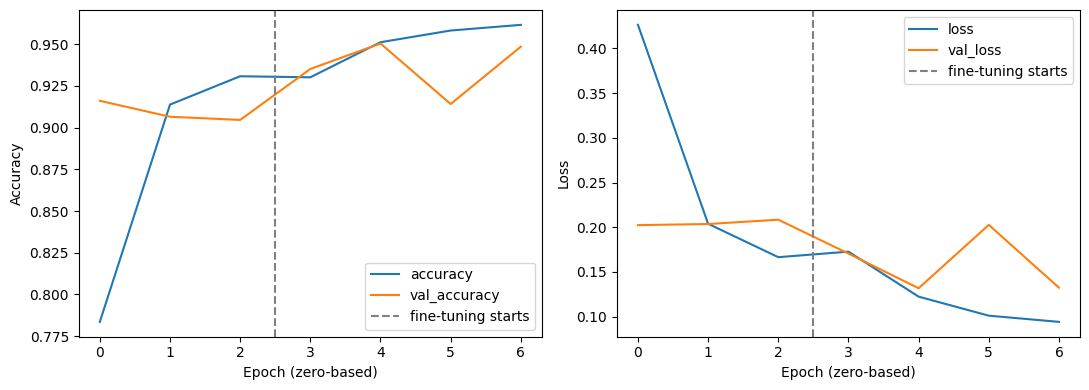

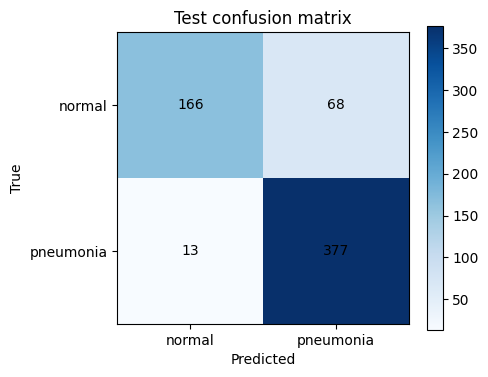

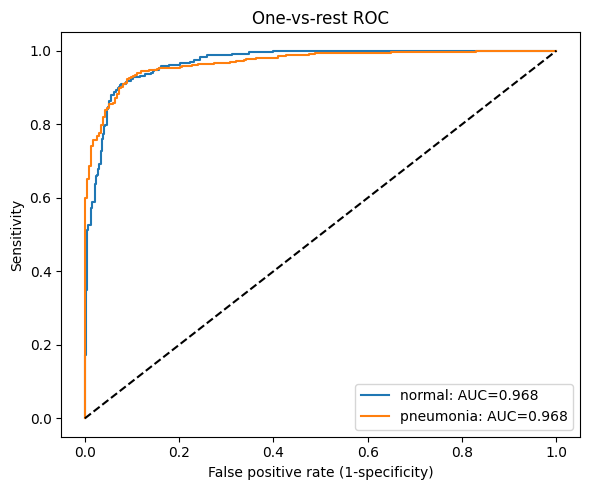

1050

In [5]:
val_scores=model.evaluate(val_ds,return_dict=True,verbose=0)
test_scores=model.evaluate(test_ds,return_dict=True,verbose=0)
prob=model.predict(test_ds,verbose=0).reshape(-1)
truth=labels['test']; pred=(prob>=.5).astype(int)
cm=confusion_matrix(truth,pred,labels=[0,1])
tn,fp,fn,tp=cm.ravel()
results={'model':'MobileNetV2 ImageNet','dataset':'PneumoniaMNIST-64',
         'seed':SEED,'input_size':IMAGE_SIZE,'selected_stage':selected,
         'head_best_val_loss':head_val_loss,'finetuned_best_val_loss':fine_val_loss,
         'validation':{k:float(v) for k,v in val_scores.items()},
         'test':{k:float(v) for k,v in test_scores.items()},
         'test_roc_auc':float(roc_auc_score(truth,prob)),
         'test_balanced_accuracy':float(balanced_accuracy_score(truth,pred)),
         'test_sensitivity':float(tp/(tp+fn)),'test_specificity':float(tn/(tn+fp)),
         'confusion_matrix':cm.tolist(),
         'epochs_completed':{'head':len(head.history['loss']),'finetuned':len(fine.history['loss'])},
         'tensorflow_version':tf.__version__,'python_version':platform.python_version()}
(OUT/'results.json').write_text(json.dumps(results,indent=2))
np.savez(OUT/'test_predictions.npz',labels=truth,probabilities=prob)
print(json.dumps(results,indent=2))
print(classification_report(truth,pred,target_names=['normal','pneumonia'],zero_division=0))

fig,axes=plt.subplots(1,2,figsize=(11,4))
for key in ['accuracy','val_accuracy']:
    axes[0].plot(head.history[key]+fine.history[key],label=key)
for key in ['loss','val_loss']:
    axes[1].plot(head.history[key]+fine.history[key],label=key)
for ax in axes:
    ax.axvline(len(head.history['loss'])-.5,color='gray',ls='--',label='fine-tuning starts')
    ax.set_xlabel('Epoch (zero-based)');ax.legend()
axes[0].set_ylabel('Accuracy');axes[1].set_ylabel('Loss')
fig.tight_layout();fig.savefig(OUT/'training_curves.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(cm,cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['normal','pneumonia'],
       yticklabels=['normal','pneumonia'],xlabel='Predicted',ylabel='True',title='Test confusion matrix')
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'confusion_matrix.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(6,5))
for c,name in enumerate(['normal','pneumonia']):
    fpr,tpr,_=roc_curve((truth==c).astype(int),1-prob if c==0 else prob)
    ax.plot(fpr,tpr,label=f'{name}: AUC={auc(fpr,tpr):.3f}')
ax.plot([0,1],[0,1],'k--');ax.set(xlabel='False positive rate (1-specificity)',ylabel='Sensitivity',title='One-vs-rest ROC')
ax.legend();fig.tight_layout();fig.savefig(OUT/'roc.png',dpi=180);plt.show()

writeup=f'''# Part 2: Medical image fine-tuning
We used ImageNet-pretrained MobileNetV2 on PneumoniaMNIST-64 with the official 4,708/524/624 train/validation/test split. Grayscale images were repeated into RGB and resized to 96×96; upsampling cannot recover lost detail. We trained a new classifier at learning rate 0.001, then fine-tuned the final 30 backbone layers (excluding batch normalization) at 0.00001. Training used class weights computed from training data only. Checkpoints were selected by validation loss.

Selected stage: {selected}. Validation accuracy: {val_scores['accuracy']:.4f}. Test accuracy: {test_scores['accuracy']:.4f}. Test ROC AUC: {results['test_roc_auc']:.4f}. Test sensitivity: {results['test_sensitivity']:.4f}; specificity: {results['test_specificity']:.4f}. Head-only best validation loss: {head_val_loss:.4f}; fine-tuned best validation loss: {fine_val_loss:.4f}.

Limitations include low source image resolution, class imbalance, and evaluation on one benchmark split. These results do not establish clinical diagnostic performance. Patient-level independence has not been independently audited.

Sources: https://medmnist.com/ and https://keras.io/guides/transfer_learning/
'''
(OUT/'writeup.md').write_text(writeup)


## Optional: t-SNE of final pooled backbone features
Visualization uses test features after model selection; it does not affect fitting or checkpoint choice. Clusters are exploratory and are not evidence of clinical validity.


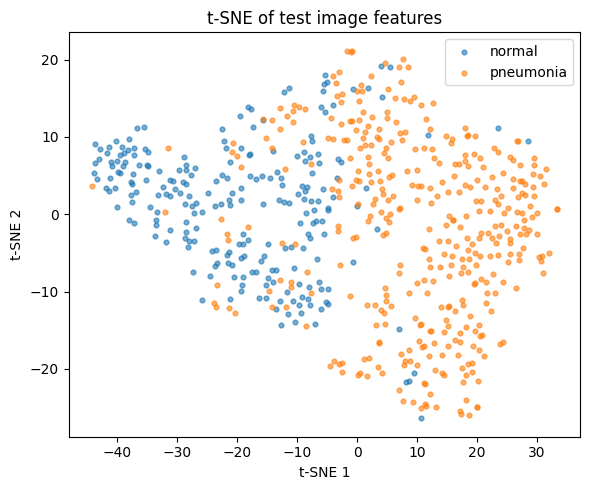

In [6]:
from sklearn.manifold import TSNE
features=keras.Model(model.input,model.get_layer('features').output).predict(test_ds,verbose=0)
embedding=TSNE(n_components=2,random_state=SEED,init='pca',learning_rate='auto',perplexity=30).fit_transform(features)
fig,ax=plt.subplots(figsize=(6,5))
for c,name in enumerate(['normal','pneumonia']):
    idx=truth==c;ax.scatter(embedding[idx,0],embedding[idx,1],s=12,alpha=.6,label=name)
ax.set(title='t-SNE of test image features',xlabel='t-SNE 1',ylabel='t-SNE 2');ax.legend()
fig.tight_layout();fig.savefig(OUT/'tsne.png',dpi=180);plt.show()


In [7]:
# Save the executed notebook in Colab, and download this archive of model/results.
archive=Path('part2_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as bundle:
    for file in OUT.rglob('*'):
        if file.is_file(): bundle.write(file,file.relative_to(OUT.parent))
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Results saved at',archive.resolve())


Results saved at ./part2_results.zip


## Post-selection error review and uncertainty

Additional descriptive analysis executed in a separate session after the original
training run. No model fitting or threshold selection is performed. Wilson
intervals are image-level approximations; AUC uses 2,000 stratified bootstrap
resamples. These intervals do not establish patient-level independence or external
validity. Examples are the four most confidently wrong cases in each direction,
selected to expose failures.


{
  "accuracy": {
    "estimate": 0.8701923076923077,
    "ci95_wilson": [
      0.8415404700915927,
      0.894314089223107
    ],
    "correct": 543,
    "total": 624
  },
  "pneumonia_sensitivity": {
    "estimate": 0.9666666666666667,
    "ci95_wilson": [
      0.9438116466442524,
      0.9804181210646871
    ],
    "correct": 377,
    "total": 390
  },
  "normal_specificity": {
    "estimate": 0.7094017094017094,
    "ci95_wilson": [
      0.6482177492789027,
      0.763821432140183
    ],
    "correct": 166,
    "total": 234
  },
  "pneumonia_precision": {
    "estimate": 0.8471910112359551,
    "ci95_wilson": [
      0.8108007781904881,
      0.8776382996341857
    ],
    "correct": 377,
    "total": 445
  },
  "normal_recall": {
    "estimate": 0.7094017094017094,
    "ci95_wilson": [
      0.6482177492789027,
      0.763821432140183
    ],
    "correct": 166,
    "total": 234
  },
  "roc_auc": {
    "estimate": 0.9681349989042297,
    "ci95_stratified_bootstrap": [
      0.955

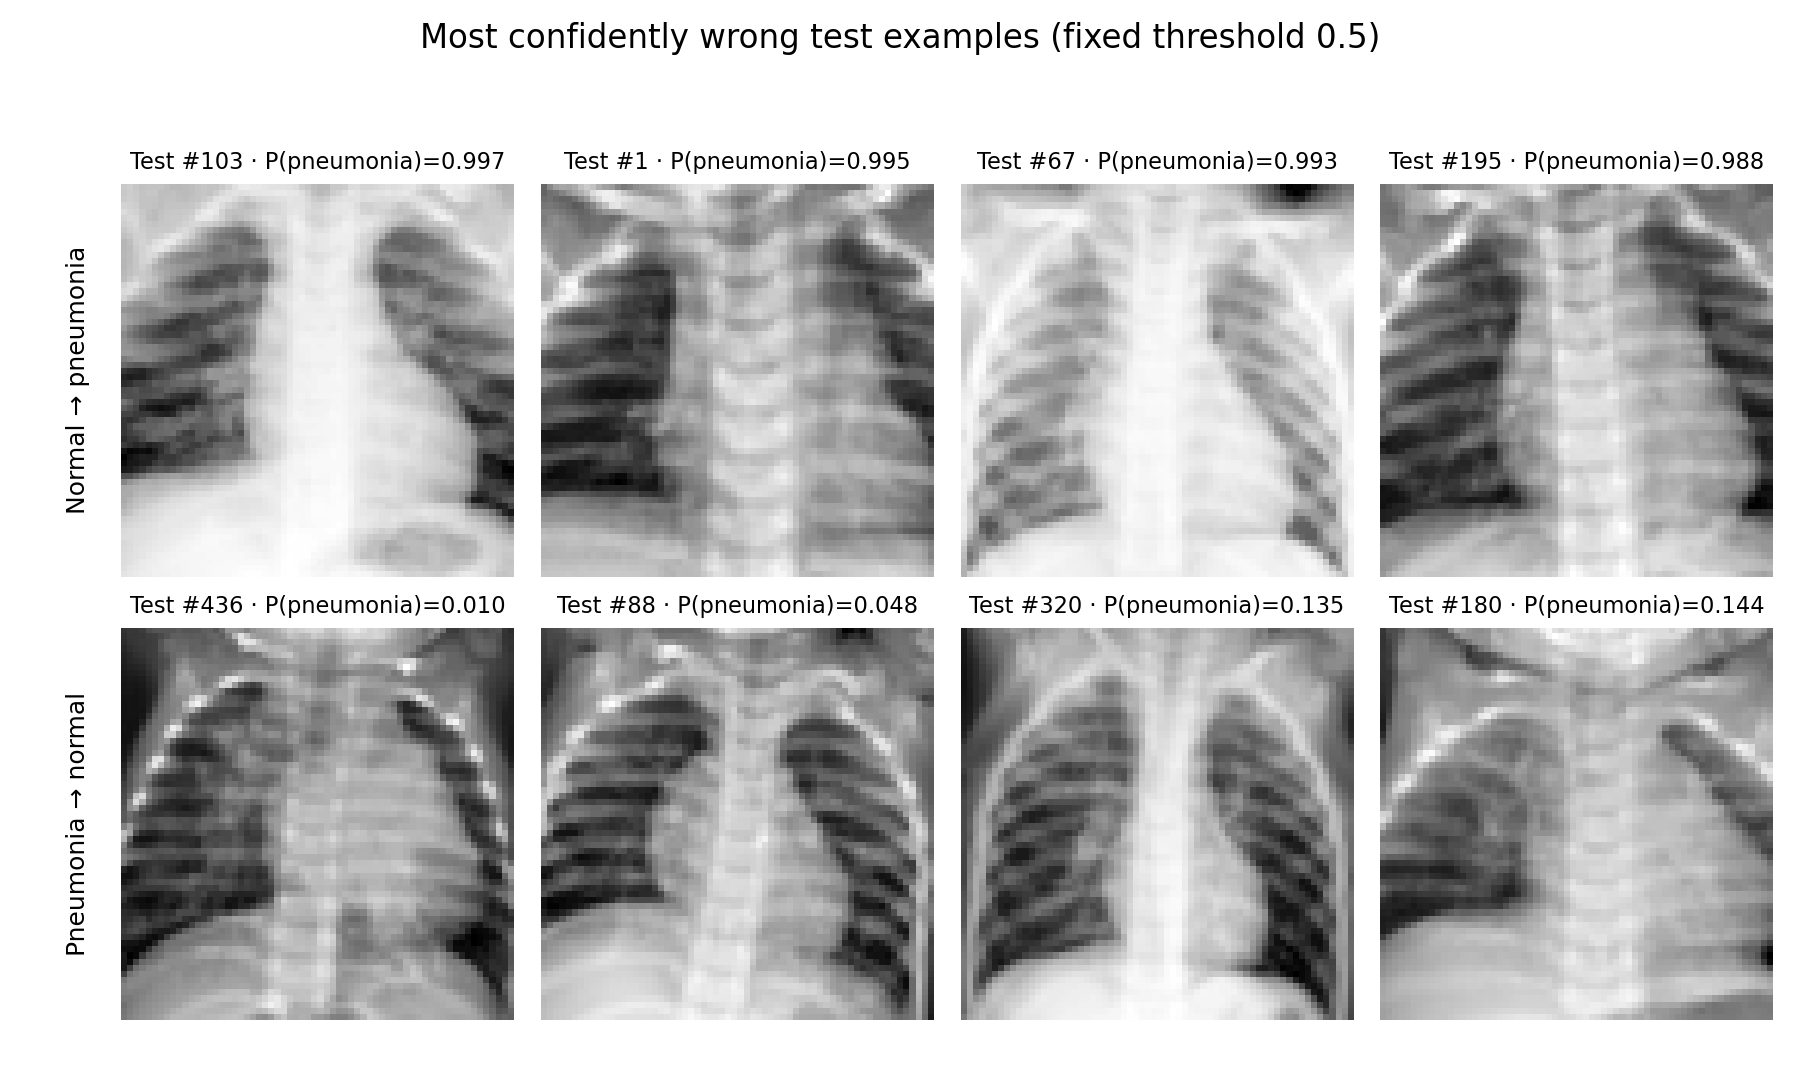

In [1]:
"""Post-selection error review; no training, threshold tuning or model selection."""
import json
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score


def wilson(correct, total):
    z = 1.959963984540054
    p = correct / total
    denom = 1 + z*z/total
    center = (p + z*z/(2*total))/denom
    radius = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total))/denom
    return [float(center-radius), float(center+radius)]


def review(images, truth, probability, out):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    truth = np.asarray(truth).reshape(-1)
    probability = np.asarray(probability).reshape(-1)
    assert len(images) == len(truth) == len(probability)
    assert set(np.unique(truth)) == {0, 1} and np.isfinite(probability).all()
    pred = probability >= .5
    tn = int(np.sum((truth == 0) & ~pred)); fp = int(np.sum((truth == 0) & pred))
    fn = int(np.sum((truth == 1) & ~pred)); tp = int(np.sum((truth == 1) & pred))
    metrics = {}
    for name, correct, total in [('accuracy', tn+tp, len(truth)),
                                  ('pneumonia_sensitivity', tp, tp+fn),
                                  ('normal_specificity', tn, tn+fp),
                                  ('pneumonia_precision', tp, tp+fp),
                                  ('normal_recall', tn, tn+fp)]:
        metrics[name] = {'estimate': correct/total, 'ci95_wilson': wilson(correct, total),
                         'correct': correct, 'total': total}
    # Stratification preserves the official test class counts in each resample.
    rng = np.random.default_rng(2026)
    groups = [np.flatnonzero(truth == c) for c in (0, 1)]
    aucs = []
    for _ in range(2000):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
        aucs.append(roc_auc_score(truth[idx], probability[idx]))
    metrics['roc_auc'] = {'estimate': float(roc_auc_score(truth, probability)),
                          'ci95_stratified_bootstrap': np.quantile(aucs, [.025, .975]).tolist(),
                          'resamples': 2000, 'seed': 2026}
    result = {'scope': 'Post-hoc descriptive analysis of the unchanged selected model at threshold 0.5.',
              'metrics': metrics, 'confusion_matrix': [[tn, fp], [fn, tp]],
              'majority_class_test_accuracy': float(np.mean(truth == 1)),
              'interval_limitation': 'Image-level intervals assume independent test images. Patient grouping and external validity are not established; AUC bootstrap conditions on class counts.',
              'error_example_selection': 'Four most confidently wrong examples per error type; test split indices are zero based.',
              'examples': []}
    fig, axes = plt.subplots(2, 4, figsize=(10, 6))
    for row, (mask, title, reverse) in enumerate([
            ((truth == 0) & pred, 'Normal → pneumonia', True),
            ((truth == 1) & ~pred, 'Pneumonia → normal', False)]):
        idx = np.flatnonzero(mask)
        order = np.argsort(probability[idx], kind='stable')
        if reverse: order = order[::-1]
        selected = idx[order[:4]]
        for col, ax in enumerate(axes[row]):
            ax.axis('off')
            if col >= len(selected): continue
            i = int(selected[col]); ax.imshow(images[i].squeeze(), cmap='gray')
            ax.set_title(f'Test #{i} · P(pneumonia)={probability[i]:.3f}', fontsize=9)
            result['examples'].append({'test_index': i, 'true_label': int(truth[i]),
                                       'prediction': int(pred[i]), 'pneumonia_probability': float(probability[i])})
        axes[row, 0].text(-.08, .5, title, transform=axes[row, 0].transAxes,
                          rotation=90, ha='right', va='center', fontsize=10)
    fig.suptitle('Most confidently wrong test examples (fixed threshold 0.5)', fontsize=13)
    fig.tight_layout(rect=(.025, 0, 1, .94)); fig.savefig(out/'error_examples.png', dpi=180)
    plt.close(fig)
    (out/'error_analysis.json').write_text(json.dumps(result, indent=2))
    lines = ['# Error review and uncertainty', '',
             'The model and 0.5 decision threshold are unchanged. These analyses were performed after selection; test errors were not used to retrain or choose a threshold.', '',
             '| Metric | Estimate | 95% interval |', '|---|---:|---:|']
    for name, value in metrics.items():
        interval = value.get('ci95_wilson', value.get('ci95_stratified_bootstrap'))
        lines.append(f"| {name} | {value['estimate']:.4f} | {interval[0]:.4f}–{interval[1]:.4f} |")
    lines += ['', f'The majority-class test baseline is {result["majority_class_test_accuracy"]:.2%}. '
              f'There are {fp} false positives among {tn+fp} normal images and {fn} false negatives among {tp+fn} pneumonia images. '
              'High pneumonia sensitivity therefore coexists with substantially lower normal specificity.', '',
              'The montage deliberately shows the four most confidently wrong examples in each direction. '
              'It demonstrates failures rather than diagnosing their causes. The validation/test gap could reflect split differences or model generalization; these data do not isolate a cause.', '',
              result['interval_limitation']]
    (out/'error_analysis.md').write_text('\n'.join(lines)+'\n')
    print(json.dumps(result['metrics'], indent=2))
    return result



# Reuse predictions after Run all; a separate local review uses saved outputs.
if 'images' in globals() and 'prob' in globals():
    review_images, review_truth, review_prob = images['test'], truth, prob
else:
    with np.load('data/part2/medmnist/pneumoniamnist_64.npz') as a:
        review_images = a['test_images']
    with np.load('results/part2/test_predictions.npz') as a:
        review_truth, review_prob = a['labels'], a['probabilities']
review_result = review(review_images, review_truth, review_prob, Path('results/part2'))
from IPython.display import display, Image
display(Image(filename='results/part2/error_examples.png'))
